# Task 2: Exploratory Data Analysis

## Introduction
This notebook explores business patterns in the cleaned e-commerce order-item dataset created in Task 1. It focuses on order activity, sales, categories, payments, time trends, and relationships between numeric fields.

## What is EDA and why is it useful?
Exploratory data analysis (EDA) uses summaries and visualizations to understand patterns, comparisons, and relationships in data. It helps turn a dataset into practical questions and findings before any modeling is considered.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

## Load the cleaned dataset
The cleaned CSV is stored in the project's `Dataset` folder. This notebook reads it using a path relative to `Task_2`. Run Task 1 first whenever the original data or cleaning steps have changed.


In [2]:
df = pd.read_csv("../Dataset/Cleaned_Dataset.csv", low_memory=False)

print(f"Loaded {len(df):,} order-item rows across {df['increment_id'].nunique():,} unique orders.")
display(df.head())


Loaded 584,524 order-item rows across 408,782 unique orders.


,item_id,status,created_at,sku,price,qty_ordered,grand_total,increment_id,category_name_1,sales_commission_code,discount_amount,payment_method,Working Date,BI Status,MV,Year,Month,Customer Since,M-Y,FY,Customer ID
0,211131,complete,07/01/2016,kreations_YI 06-L,1950.0,1,1950.0,100147443,Women's Fashion,NaN,0.0,cod,07/01/2016,NaN,"1,950",2016,7,2016-7,Jul-16,FY17,1.0
1,211133,canceled,07/01/2016,kcc_Buy 2 Frey Air Freshener & Get 1 Kasual Bo...,240.0,1,240.0,100147444,Beauty & Grooming,NaN,0.0,cod,07/01/2016,Gross,240,2016,7,2016-7,Jul-16,FY17,2.0
2,211134,canceled,07/01/2016,Ego_UP0017-999-MR0,2450.0,1,2450.0,100147445,Women's Fashion,NaN,0.0,cod,07/01/2016,Gross,"2,450",2016,7,2016-7,Jul-16,FY17,3.0
3,211135,complete,07/01/2016,kcc_krone deal,360.0,1,60.0,100147446,Beauty & Grooming,R-FSD-52352,300.0,cod,07/01/2016,Net,360,2016,7,2016-7,Jul-16,FY17,4.0
4,211136,order_refunded,07/01/2016,BK7010400AG,555.0,2,1110.0,100147447,Soghaat,NaN,0.0,cod,07/01/2016,Valid,"1,110",2016,7,2016-7,Jul-16,FY17,5.0


The file is loaded with 21 fields and the expected order-item records. The remaining missing values are documented in Task 1; this notebook uses the cleaned data as-is and does not repeat the cleaning process.

## Unit of analysis
Each row represents one order item, while an order can contain multiple item rows. The cleaning decisions and basic descriptive statistics are covered in Task 1; this notebook focuses on business comparisons and trends. Whenever the analysis is at order level, each `increment_id` is counted once.


## Set up the sales analysis
The `grand_total` field repeats the order amount on multiple item rows for some orders, so summing it across rows could count the same order more than once. Instead, I calculate item sales as `price × qty_ordered − discount_amount`. I describe an order as fulfilled when its status is `complete` or `received`; other statuses remain included in the separate order-status analysis.

In [3]:
df["created_at"] = pd.to_datetime(
    df["created_at"], format="%m/%d/%Y", errors="coerce"
)
df["item_sales"] = df["price"] * df["qty_ordered"] - df["discount_amount"]

fulfilled_statuses = ["complete", "received"]
fulfilled = df[df["status"].isin(fulfilled_statuses)].copy()

print("Date range:", df["created_at"].min().date(), "to", df["created_at"].max().date())
print("Fulfilled order-item rows:", len(fulfilled))
print("Fulfilled unique orders:", fulfilled["increment_id"].nunique())
print("Fulfilled item sales total:", round(fulfilled["item_sales"].sum(), 2))

Date range: 2016-07-01 to 2018-08-28
Fulfilled order-item rows: 310994
Fulfilled unique orders: 205321
Fulfilled item sales total: 1216863948.0


Dates are parsed using the month/day/year format in the source file. The dataset covers July 2016 through August 2018, so the first and last years are partial periods.

## Yearly sales analysis
The yearly table sums item sales for completed or received orders and also counts unique orders. The partial years should not be compared as if they cover equal time periods.

,item_sales,unique_orders
created_at,,
2016,1.569499e+08,61802
2017,5.707777e+08,93405
2018,4.891364e+08,50114


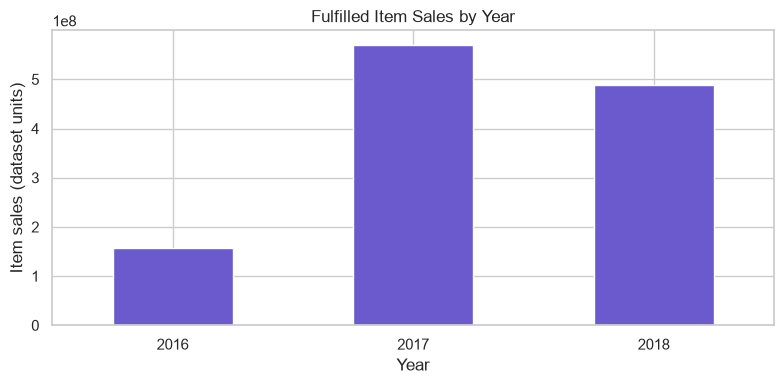

In [4]:
yearly_sales = fulfilled.groupby(fulfilled["created_at"].dt.year).agg(
    item_sales=("item_sales", "sum"),
    unique_orders=("increment_id", "nunique")
)
display(yearly_sales.round(2))

yearly_sales["item_sales"].plot(kind="bar", color="slateblue", figsize=(8, 4))
plt.title("Fulfilled Item Sales by Year")
plt.xlabel("Year")
plt.ylabel("Item sales (dataset units)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

The yearly totals are highest in 2017. The 2016 data starts in July and 2018 ends in August, so these totals cover fewer months than 2017 and should not be interpreted as full-year comparisons.

## Monthly sales trend
Grouping by month makes it easier to see how fulfilled item sales change over time. Each point represents the sum of item-level sales for that month.

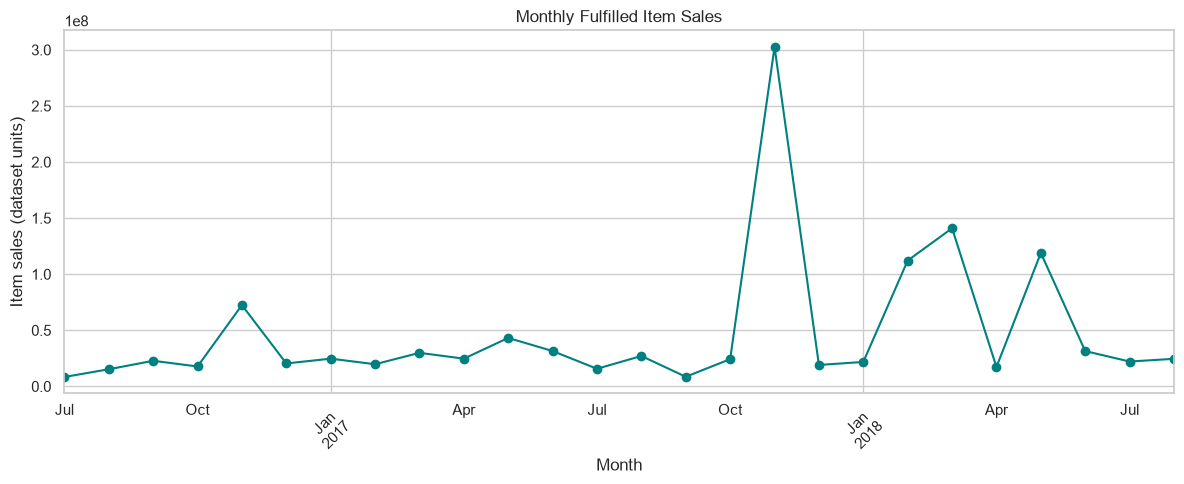

Highest month: November 2017 - 302551729.96
Lowest month: July 2016 - 8364691.09


In [5]:
monthly_sales = fulfilled.groupby(
    fulfilled["created_at"].dt.to_period("M")
)["item_sales"].sum()
monthly_sales.index = monthly_sales.index.to_timestamp()

plt.figure(figsize=(12, 5))
monthly_sales.plot(marker="o", color="teal")
plt.title("Monthly Fulfilled Item Sales")
plt.xlabel("Month")
plt.ylabel("Item sales (dataset units)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

peak_month = monthly_sales.idxmax()
low_month = monthly_sales.idxmin()
print("Highest month:", peak_month.strftime("%B %Y"), "-", round(monthly_sales.max(), 2))
print("Lowest month:", low_month.strftime("%B %Y"), "-", round(monthly_sales.min(), 2))

The monthly chart includes a pronounced peak in November 2017. July 2016 is the lowest month in this dataset, but it is also the first month recorded, so the series should be interpreted within the available date range.

## Category-wise sales
This comparison sums the item-level sales estimate within each product category. It includes only complete and received orders, following the sales definition above.

,item_sales,unique_orders,sales_share_percent
category_name_1,,,
Mobiles & Tablets,5.835087e+08,49223,47.95
Appliances,2.067151e+08,23115,16.99
Entertainment,1.845389e+08,11162,15.17
Others,5.181805e+07,8590,4.26
Women's Fashion,4.919051e+07,21448,4.04
Computing,4.022136e+07,6565,3.31
Men's Fashion,3.670093e+07,37939,3.02
Beauty & Grooming,1.801317e+07,19092,1.48
Superstore,1.535053e+07,13153,1.26


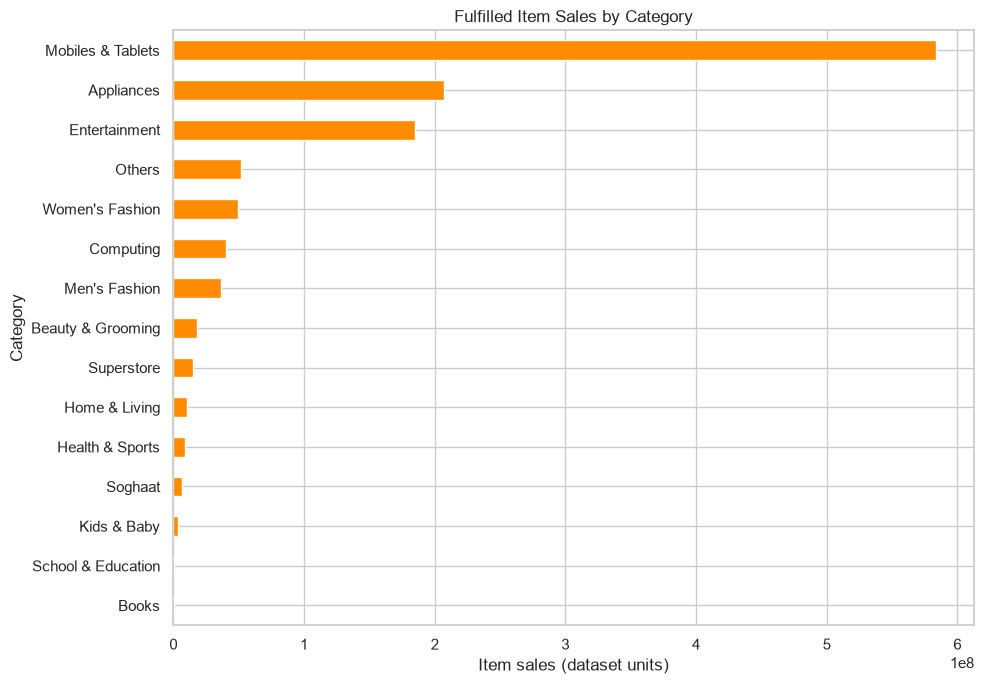

In [6]:
category_sales = fulfilled.groupby("category_name_1").agg(
    item_sales=("item_sales", "sum"),
    unique_orders=("increment_id", "nunique")
).sort_values("item_sales", ascending=False)
category_sales["sales_share_percent"] = (
    category_sales["item_sales"] / category_sales["item_sales"].sum() * 100
)
display(category_sales.round(2))

category_sales["item_sales"].sort_values().plot(
    kind="barh", figsize=(10, 7), color="darkorange"
)
plt.title("Fulfilled Item Sales by Category")
plt.xlabel("Item sales (dataset units)")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

Mobiles & Tablets contributes the largest fulfilled item-sales total and accounts for nearly half of the total. Appliances and Entertainment are the next largest categories in this measure.

## Payment method analysis
Payment methods are compared by unique orders, not item rows, so multi-item orders are counted once. The pie chart shows the eight most common methods and combines the remaining methods as `Other`.

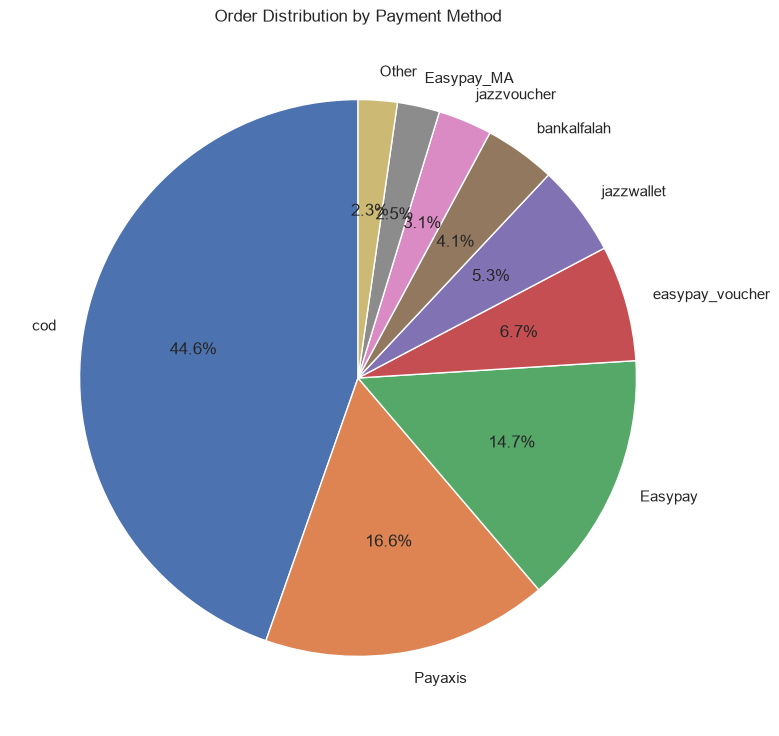

,unique_orders
payment_method,
cod,182449
Payaxis,67912
Easypay,60278
easypay_voucher,27505
jazzwallet,21613
bankalfalah,16912
jazzvoucher,12809
Easypay_MA,10050
customercredit,5120


In [7]:
order_summary = df.drop_duplicates(subset="increment_id")
payment_orders = order_summary["payment_method"].value_counts()
payment_top = payment_orders.head(8).copy()
if len(payment_orders) > 8:
    payment_top["Other"] = payment_orders.iloc[8:].sum()

plt.figure(figsize=(8, 8))
plt.pie(
    payment_top,
    labels=payment_top.index,
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={"edgecolor": "white"}
)
plt.title("Order Distribution by Payment Method")
plt.tight_layout()
plt.show()

display(payment_orders.head(10).to_frame("unique_orders"))

Cash on delivery is the most common payment method by unique order count. The other payment methods still account for a substantial part of activity, so payment preferences are not limited to one method.

## Order status analysis
Each order is counted once by its status. This gives an order-level view of completed, canceled, refunded, and other recorded statuses.

,unique_orders
status,
complete,169515
canceled,148656
order_refunded,49067
received,35806
refund,4091
cod,880
closed,332
paid,294
pending,43


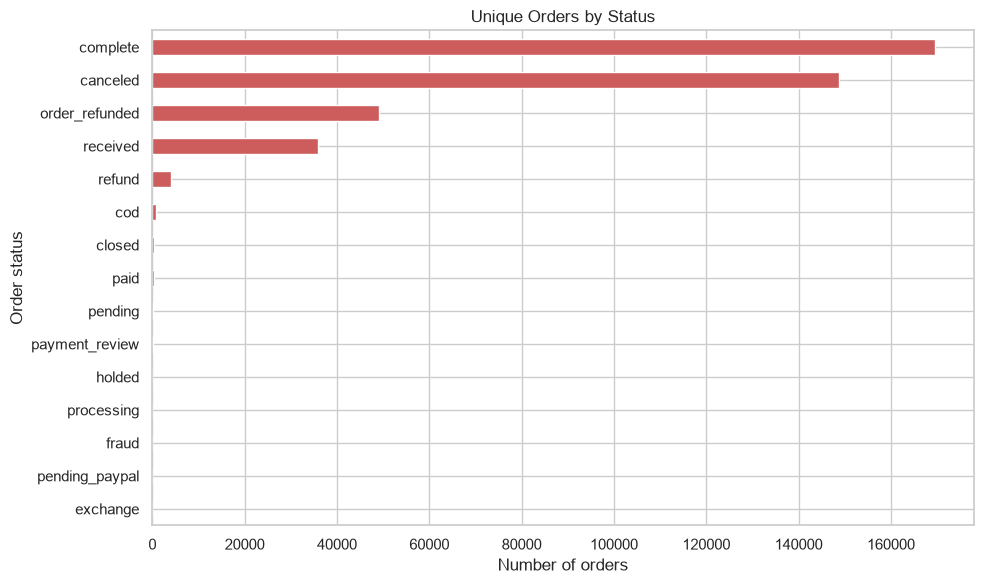

In [8]:
orders_by_status = order_summary["status"].value_counts().sort_values()
display(orders_by_status.sort_values(ascending=False).to_frame("unique_orders"))

plt.figure(figsize=(10, 6))
orders_by_status.plot(kind="barh", color="indianred")
plt.title("Unique Orders by Status")
plt.xlabel("Number of orders")
plt.ylabel("Order status")
plt.tight_layout()
plt.show()

Canceled orders form a large share of the order-status counts. This is worth investigating further, while remembering that status labels describe order outcomes and are not the same as fulfilled sales.

## Relationship between price and quantity
The scatter plot uses a reproducible sample of up to 5,000 fulfilled item rows. The axes are limited to the 99th percentiles to make the dense main portion easier to see; the underlying records are not removed from the analysis.

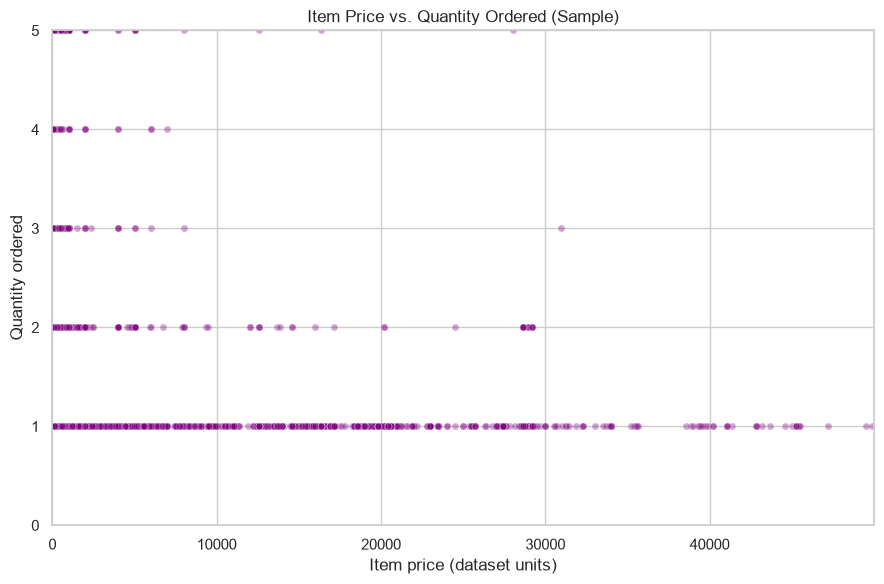

Price-quantity correlation in fulfilled rows: -0.019


In [9]:
scatter_data = fulfilled.sample(
    n=min(5000, len(fulfilled)), random_state=42
)
price_limit = fulfilled["price"].quantile(0.99)
quantity_limit = fulfilled["qty_ordered"].quantile(0.99)

plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=scatter_data,
    x="price",
    y="qty_ordered",
    alpha=0.35,
    s=25,
    color="purple"
)
plt.xlim(0, price_limit)
plt.ylim(0, quantity_limit)
plt.title("Item Price vs. Quantity Ordered (Sample)")
plt.xlabel("Item price (dataset units)")
plt.ylabel("Quantity ordered")
plt.tight_layout()
plt.show()

print("Price-quantity correlation in fulfilled rows:", round(
    fulfilled["price"].corr(fulfilled["qty_ordered"]), 3
))

The plotted sample is concentrated at low quantities, with many records at one item per row. The displayed axes omit only the farthest 1% at the high end of each variable to make the main cluster visible; the reported correlation uses all fulfilled rows.

## Correlation analysis
The heatmap summarizes linear correlations among item price, quantity, discount, and the calculated item-sales amount. Correlation describes association, not proof that one variable causes another.

,price,qty_ordered,discount_amount,item_sales
price,1.000,-0.019,0.649,0.383
qty_ordered,-0.019,1.000,-0.010,0.792
discount_amount,0.649,-0.010,1.000,0.223
item_sales,0.383,0.792,0.223,1.000


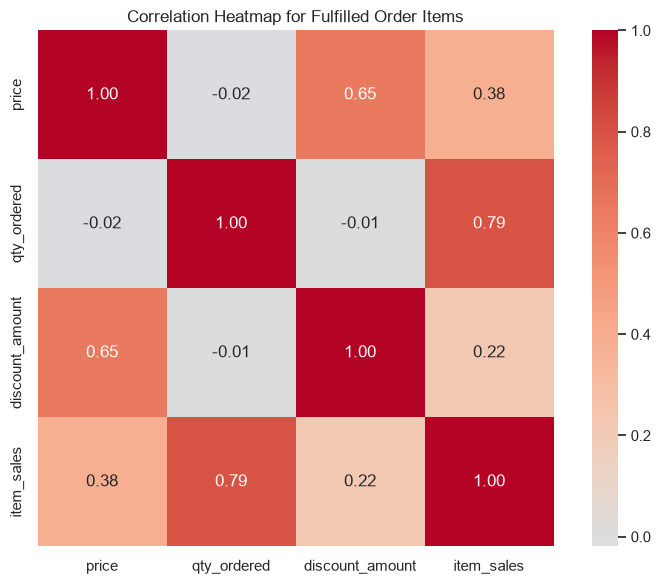

In [10]:
correlation_columns = [
    "price", "qty_ordered", "discount_amount", "item_sales"
]
correlation_matrix = fulfilled[correlation_columns].corr()
display(correlation_matrix.round(3))

plt.figure(figsize=(8, 6))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f",
    square=True
)
plt.title("Correlation Heatmap for Fulfilled Order Items")
plt.tight_layout()
plt.show()

Quantity and calculated item sales have a positive relationship in this dataset. Price and item sales are also positively related, but less strongly. These patterns are expected in part because price and quantity are inputs to the item-sales calculation.

## Top 10 products by fulfilled item sales
The product field is `sku`. This chart ranks products by the same item-sales measure used above and only includes complete and received orders.

,item_sales
sku,
MATSAM59DB75ADB2F80,33020251.37
MATSAM59DB757FB47A2,21353401.00
IDROID_BALRX7-Gold,13388824.55
MATSAM59D74470AD085,13384281.00
MATSAM5A7463EE3C1A5,13245643.58
MATSAM5A0BFFF19C40A,11984731.00
ENTECO5A7FE80D6C830,11941452.85
infinix_Zero 4-Grey,10583427.44
MATSAM5A7DBC6689BE5,10100631.20


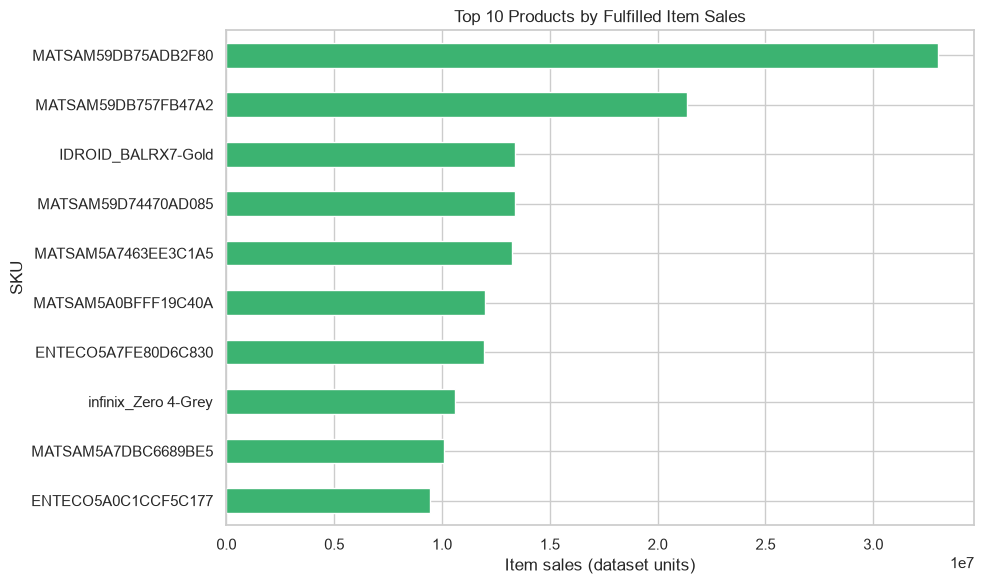

In [11]:
product_sales = fulfilled.groupby("sku")["item_sales"].sum().sort_values(ascending=False)
top_products = product_sales.head(10).sort_values()
display(product_sales.head(10).to_frame("item_sales").round(2))

plt.figure(figsize=(10, 6))
top_products.plot(kind="barh", color="mediumseagreen")
plt.title("Top 10 Products by Fulfilled Item Sales")
plt.xlabel("Item sales (dataset units)")
plt.ylabel("SKU")
plt.tight_layout()
plt.show()

The product chart shows that sales value is not distributed evenly across SKUs. The leading products are useful candidates for inventory and availability checks, but the dataset does not include product costs or profit margins.

## Findings from this dataset
The following observations use the order-level counts and fulfilled item-sales measure defined above:

1. There are **408,782 unique orders** in the dataset, of which **205,321** have a `complete` or `received` status.
2. Fulfilled item sales total approximately **1,216,863,948 dataset units** using price × quantity minus discount.
3. **Mobiles & Tablets** is the largest fulfilled sales category, with approximately **583,508,701 dataset units** (about **48.0%** of fulfilled item sales).
4. **Cash on delivery** is the most common payment method, used for **182,449 orders** (about **44.6%** of all unique orders).
5. There are **148,656 canceled orders**, approximately **36.4%** of all unique orders.
6. **November 2017** is the highest fulfilled-sales month in the available period, at approximately **302,551,730 dataset units**. The series covers July 2016 to August 2018, not complete calendar years.

These results describe the available records and should be interpreted using the definitions and date coverage noted above.

## Actionable business recommendations

- Investigate the cancellation journey by product category and payment method to learn where customers drop out; use the findings to improve order confirmation and checkout follow-up.
- Protect availability for high-sales categories and leading SKUs, while monitoring stock levels and supplier reliability during the November sales peak.
- Keep cash on delivery convenient because it is the leading payment method, and test clear incentives for alternative methods without removing customer choice.
- Plan promotions and fulfillment capacity around observed monthly peaks, but compare like-for-like periods because this dataset starts and ends partway through a year.
- Review margins and return rates before making profitability decisions. This dataset has prices and discounts but no product costs, so sales value alone cannot show profit.

## Task 2 conclusion
The EDA shows substantial differences in sales across categories and months, a strong reliance on cash on delivery, and a high count of canceled orders. Item-level calculations avoid summing repeated order totals, and order-level counts avoid counting multi-item orders more than once. The dataset is useful for identifying areas to investigate, but its partial date range, order statuses, and lack of cost data should be considered before making financial decisions.